
# 02 — Prever dígitos manuscritos

Este notebook carrega o modelo MLP treinado e salvo pelo notebook `01_treinar_mlp.ipynb` para classificar imagens externas de dígitos manuscritos, sem executar novamente o treinamento.


1. Importações

In [1]:
from pathlib import Path

import joblib
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import tkinter as tk
from tkinter import filedialog

PROJECT_DIR = Path.cwd().parent

MODEL_PATH = PROJECT_DIR / "models" / "mlp_mnist.joblib"
IMAGES_DIR = PROJECT_DIR / "data" / "external_images"

IMAGES_DIR.mkdir(parents=True, exist_ok=True)

print(f"Modelo: {MODEL_PATH}")
print(f"Pasta de imagens: {IMAGES_DIR}")

Modelo: d:\Users\Deepen\Box\Box Sync\Capacitação\Cursos Online\SENAI\Desenvolvimento IA M2\Projeto final\models\mlp_mnist.joblib
Pasta de imagens: d:\Users\Deepen\Box\Box Sync\Capacitação\Cursos Online\SENAI\Desenvolvimento IA M2\Projeto final\data\external_images


2. Carregar o modelo treinado

In [2]:
if not MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Modelo não encontrado: {MODEL_PATH}. "
        "Execute primeiro o notebook 01_treinar_mlp.ipynb."
    )

modelo = joblib.load(MODEL_PATH)

print("Modelo carregado com sucesso.")
print(f"Classes conhecidas: {modelo.classes_}")

Modelo carregado com sucesso.
Classes conhecidas: [0 1 2 3 4 5 6 7 8 9]


3. Selecionar a imagem

In [3]:
janela_selecao = tk.Tk()
janela_selecao.withdraw()
janela_selecao.attributes("-topmost", True)

caminho_imagem = filedialog.askopenfilename(
    parent=janela_selecao,
    title="Selecione uma imagem de dígito",
    filetypes=[
        ("Imagens", "*.png *.jpg *.jpeg"),
        ("PNG", "*.png"),
        ("JPEG", "*.jpg *.jpeg")
    ]
)

janela_selecao.destroy()

if not caminho_imagem:
    raise ValueError("Nenhuma imagem foi selecionada.")

IMAGE_PATH = Path(caminho_imagem)

print(f"Imagem selecionada: {IMAGE_PATH}")

Imagem selecionada: D:\Users\deepe\Downloads\_Imagens digitalizadas\teste_3.jpg


4. Preparar imagem

In [4]:
def preparar_imagem(caminho):
    imagem = Image.open(caminho).convert("L")

    # Inverte a imagem se o fundo for escuro.
    pixels_borda = (
        [imagem.getpixel((x, 0)) for x in range(imagem.width)]
        + [imagem.getpixel((x, imagem.height - 1)) for x in range(imagem.width)]
        + [imagem.getpixel((0, y)) for y in range(imagem.height)]
        + [imagem.getpixel((imagem.width - 1, y)) for y in range(imagem.height)]
    )

    if np.mean(pixels_borda) < 127:
        imagem = ImageOps.invert(imagem)

    # Recorta as margens quase brancas.
    matriz = np.array(imagem)
    matriz[matriz > 180] = 255
    imagem = Image.fromarray(matriz)

    # Recorta a região que contém o dígito.
    matriz = np.array(imagem)
    ys, xs = np.where(matriz < 245)

    if len(xs) > 0 and len(ys) > 0:
        imagem = imagem.crop((
            int(xs.min()),
            int(ys.min()),
            int(xs.max()) + 1,
            int(ys.max()) + 1
        ))

    # Redimensiona e centraliza em uma imagem 28 × 28.
    imagem.thumbnail((20, 20), Image.Resampling.LANCZOS)

    tela = Image.new("L", (28, 28), color=255)
    x = (28 - imagem.width) // 2
    y = (28 - imagem.height) // 2
    tela.paste(imagem, (x, y))

    # Ajusta para dígito claro sobre fundo escuro.
    tela = ImageOps.invert(tela)

    pixels = np.asarray(tela, dtype=np.float32) / 255.0

    return tela, pixels.reshape(1, 784)

5. Executar a preparação e visualizar a imagem

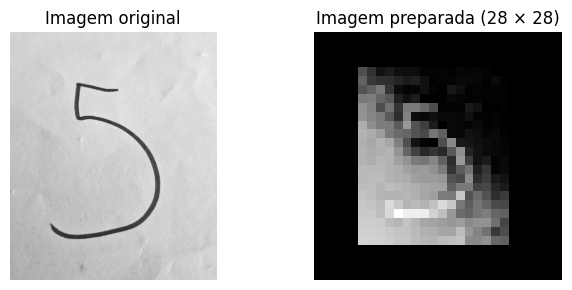

Formato para previsão: (1, 784)
Intervalo dos pixels: 0.000 a 0.478


In [5]:
imagem_preparada, X_imagem = preparar_imagem(IMAGE_PATH)

fig, axes = plt.subplots(1, 2, figsize=(7, 3))

axes[0].imshow(Image.open(IMAGE_PATH).convert("L"), cmap="gray")
axes[0].set_title("Imagem original")
axes[0].axis("off")

axes[1].imshow(imagem_preparada, cmap="gray")
axes[1].set_title("Imagem preparada (28 × 28)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print(f"Formato para previsão: {X_imagem.shape}")
print(f"Intervalo dos pixels: {X_imagem.min():.3f} a {X_imagem.max():.3f}")

5.1 - Coletar os atributos (para testes)

In [12]:
import json
import numpy as np

pixels = (np.array(imagem_preparada).flatten() / 255).tolist()

dados_api = {"pixels": pixels}

print(json.dumps(dados_api))

{"pixels": [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.14901960784313725, 0.09411764705882353, 0.03529411764705882, 0.050980392156862744, 0.027450980392156862, 0.027450980392156862, 0.023529411764705882, 0.00784313725490196, 0.00784313725490196, 0.00784313725490196, 0.00392156862745098, 0.011764705882352941, 0.00784313725490196, 0.011764705882352941, 0.00784313725490196, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.184313725490196

6. Classificar o dígito

In [26]:
previsao = int(modelo.predict(X_imagem)[0])

print(f"Dígito previsto: {previsao}")

Dígito previsto: 2


7. Exibir as probabilidades por classe

Três classes com maior probabilidade:
Dígito 6: 99.51%
Dígito 0: 0.15%
Dígito 4: 0.12%


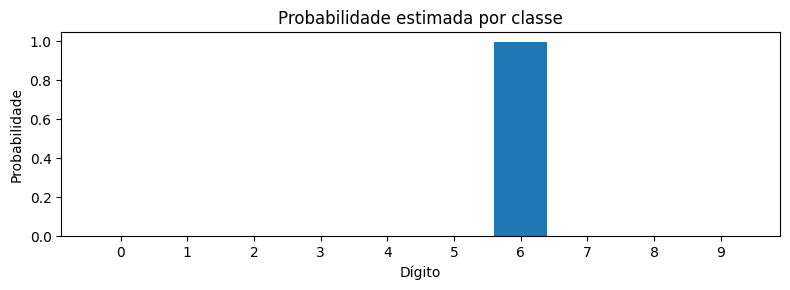

In [6]:
probabilidades = modelo.predict_proba(X_imagem)[0]
ordem = np.argsort(probabilidades)[::-1]

print("Três classes com maior probabilidade:")

for indice in ordem[:3]:
    print(
        f"Dígito {modelo.classes_[indice]}: "
        f"{probabilidades[indice]:.2%}"
    )

plt.figure(figsize=(8, 3))
plt.bar(modelo.classes_.astype(str), probabilidades)
plt.title("Probabilidade estimada por classe")
plt.xlabel("Dígito")
plt.ylabel("Probabilidade")
plt.tight_layout()
plt.show()